[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/hocmaytrongtaichinh/blob/main/Module_4/L3.ipynb)

## HỌC MÁY TRONG TÀI CHÍNH
MODULE 4 | BÀI 3


---

# **CÁC PHƯƠNG PHÁP BOOSTING**

|  |  |
|:---|:---|
|**Thời gian đọc** |  25 phút |
|**Kiến thức nền** | Phân loại, cây quyết định  |
|**Từ khóa** |Lấy mẫu có hoàn lại, hiệu suất, lượng tiếng nói (Amount of Say)  |


---

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

BASE = "https://raw.githubusercontent.com/thanhmk/hocmaytrongtaichinh/main/Module_4/"
FILES = ['Copy of default of credit card clients.xlsx']
for f in FILES:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(f), f)
        print("Đã tải:", f)

*Bài trước đã nói về các phương pháp học tập kết hợp như bagging và stacking, và áp dụng chúng vào một bài toán tài chính. Bài này nói chi tiết về một phương pháp học tập kết hợp khác là boosting thích nghi.*

## **1. Giới thiệu**

Boosting đã được nhắc ngắn gọn ở Module 3, Bài 3, và bài này sẽ bổ sung thêm. Boosting, cũng như rừng ngẫu nhiên, dùng nhiều bộ học yếu để cải thiện kết quả cuối cùng. Hãy nhớ rằng bộ học yếu là bộ học có hiệu suất chỉ tốt hơn một chút so với mô hình không có kỹ năng. Điểm khác giữa boosting và mô hình rừng ngẫu nhiên là các bộ học yếu **không** độc lập. Các bộ học này được xây dựng tuần tự, tức là một bộ học yếu "cải thiện" so với bộ học trước nó. Sự cải thiện này xảy ra khi bộ học kế tiếp tập trung vào các sai số của bộ học yếu trước. Đây là khái niệm cơ bản của boosting. Bài này sẽ giới thiệu với bạn đọc boosting *thích nghi* (adaptive).

## **2. Boosting thích nghi**

Boosting thích nghi hay AdaBoost là thuật toán phổ biến và là một trong những mô hình boosting đầu tiên được giới thiệu. Mô hình này được phát triển tuần tự bằng cách điều chỉnh trọng số hay mức độ quan trọng của các dự báo của bộ học trước. Các dự báo lệch khỏi giá trị thực được gán trọng số cao hơn, còn dự báo gần giá trị thực được gán trọng số thấp hơn. Nói cách khác, các dự báo sai được gán nhiều trọng số hơn, hay các sai số được sửa dần qua các vòng lặp. AdaBoost dùng được cho cả bài toán phân loại và hồi quy. Cần nhớ rằng AdaBoost không giới hạn ở các thuật toán dựa trên cây; tuy nhiên các bộ học yếu hay bộ học cơ sở là đồng nhất, tức là phải cùng một họ hay một loại mô hình. Như với rừng ngẫu nhiên, bỏ phiếu đa số là quyết định cuối cùng. Tuy nhiên với AdaBoost, không phải bộ học cơ sở nào cũng có trọng số hay "tiếng nói" như nhau trong cuộc bỏ phiếu. Ta sẽ dùng tập dữ liệu vỡ nợ thẻ tín dụng Đài Loan để giải thích cách AdaBoost hoạt động.

In [1]:
# import any libraries needed to create dataset
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import tree

# from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier  # , `DecisionTreeRegressor`

warnings.filterwarnings("ignore")

Tập dữ liệu này dùng để nhận diện các khoản thanh toán vỡ nợ của thẻ tín dụng ở Đài Loan. Nhóm mục tiêu là nhị phân, trong đó 1 là khách hàng vỡ nợ khi trả nợ và 0 là ngược lại. Tập dữ liệu có 22 biến dự báo. Có thể xem thêm thông tin về tập dữ liệu tại https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients . Ta nạp tập dữ liệu bên dưới.

In [2]:
data4lesson = pd.read_excel("Copy of default of credit card clients.xlsx")

In [3]:
# Make ID column the index
data4lesson.set_index("ID", inplace=True, drop=True)
data4lesson.head()

,LIMIT_BAL,SEX,EDUCATION,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
ID,,,,,,,,,,,,,,,,,,,,,
1,20000,1,2,24,2,2,-1,-1,-2,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,1,2,26,-1,2,0,0,0,2,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,1,2,34,0,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,1,2,37,0,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,0,2,57,-1,0,-1,0,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
# Rename the target column to 'Class'
data4lesson.rename(columns={"default payment next month": "Class"}, inplace=True)

# keep predictors in a separate list
feats = list(data4lesson.columns[0 : data4lesson.shape[1] - 1])

Kiểm tra số chiều của dữ liệu và tần suất của từng nhóm mục tiêu.

In [5]:
print("Rows {} columns {}".format(data4lesson.shape[0], data4lesson.shape[1]))
data4lesson["Class"].value_counts()

Rows 30000 columns 23


Class
0    23364
1     6636
Name: count, dtype: int64

Ta bắt đầu các bước của AdaBoost.

### **2.1 Bước 1: Trọng số mẫu**

Bước đầu tiên của AdaBoost là lấy mẫu ngẫu nhiên có hoàn lại trên tập dữ liệu. Để làm vậy, ban đầu ta gán cho mỗi quan sát một trọng số bằng nhau, tức là 1/N với N là số quan sát. Để giải thích quá trình lấy mẫu ngẫu nhiên, ta thêm một cột tích lũy của các trọng số tên là `RangeSelect` để minh họa ý tưởng.

In [6]:
# Assign equal weights to all samples
N = len(data4lesson)
data4lesson["probR1"] = 1 / (1.0 * N)
data4lesson["RangeSelect"] = data4lesson["probR1"].cumsum()
# Show last 5 columns
data4lesson[["PAY_AMT5", "PAY_AMT6", "Class", "probR1", "RangeSelect"]].head()

,PAY_AMT5,PAY_AMT6,Class,probR1,RangeSelect
ID,,,,,
1,0,0,1,0.000033,0.000033
2,0,2000,1,0.000033,0.000067
3,1000,5000,0,0.000033,0.000100
4,1069,1000,0,0.000033,0.000133
5,689,679,0,0.000033,0.000167


Bây giờ ta đã có cột tích lũy, ta có thể giải thích phương pháp lấy mẫu.

### **2.2 Bước 2: Lấy mẫu có hoàn lại**

Hãy xem mỗi giá trị trong cột `RangeSelect` là cận trên, còn cận dưới là giá trị của quan sát, hay dòng, đứng trước nó. Ví dụ ở kết quả trên, ID 2 có `RangeSelect` là $[0{,}000033, 0{,}000067)$. Bây giờ rút một số ngẫu nhiên trong khoảng $[0, 1]$. Giả sử số đó là $0{,}000043$. Ta thêm ID 2 vào mẫu vì số ngẫu nhiên $0{,}000043$ nằm trong khoảng $[0{,}000033, 0{,}000067)$, ứng với ID 2. Nếu số ngẫu nhiên rút ra là $0{,}00014$ thì ID 5 sẽ được thêm vào mẫu vì $0{,}00014$ nằm trong khoảng $[0{,}000133, 0{,}000167)$. Có thể thấy các quan sát có khoảng lớn sẽ có xác suất được chọn cao hơn. Do đó trọng số lớn hay giá trị `probR1` lớn làm tăng khả năng được lấy mẫu, điều này rất quan trọng với thuật toán AdaBoost. May là Python có cách lấy mẫu ngẫu nhiên có hoàn lại gọn và hiệu quả hơn, nên ta không cần cột `RangeSelect` nữa.

In [7]:
# Drop `RangeSelect` column
data4lesson.drop("RangeSelect", axis=1, inplace=True)

Ta dùng hàm *sample* của pandas để lấy mẫu có hoàn lại dựa trên cột trọng số `probR1`. Số mẫu bằng N, tức là cùng số quan sát với tập dữ liệu gốc. Tập dữ liệu mới sẽ có các quan sát trùng lặp vì việc lấy mẫu có hoàn lại.

In [8]:
# Random selection based on weights
# specify seed in case we wish to replicate
# the Random Sampling with replacement
random.seed(10)

data4lesson1 = data4lesson.sample(
    len(data4lesson), replace=True, weights=data4lesson["probR1"]
)

### **2.3 Bước 3: Khớp một bộ học cơ sở**

Bước tiếp theo của AdaBoost là khớp một bộ phân loại yếu hay bộ học cơ sở vào các mẫu. Trong ví dụ này, ta dùng cây quyết định làm bộ học cơ sở. Ta gọi bộ học này là *weak_l1* và khớp nó vào các mẫu.

In [9]:
# Since it is a stump the max depth is 1
weak_l1 = DecisionTreeClassifier(random_state=10, max_depth=1)

X = data4lesson1.loc[:, feats]
y = data4lesson1["Class"]

weak_l1.fit(X, y)

,criterion,'gini'
,splitter,'best'
,max_depth,1
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,10
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Ta có thể xem lưu đồ của gốc cây (stump).

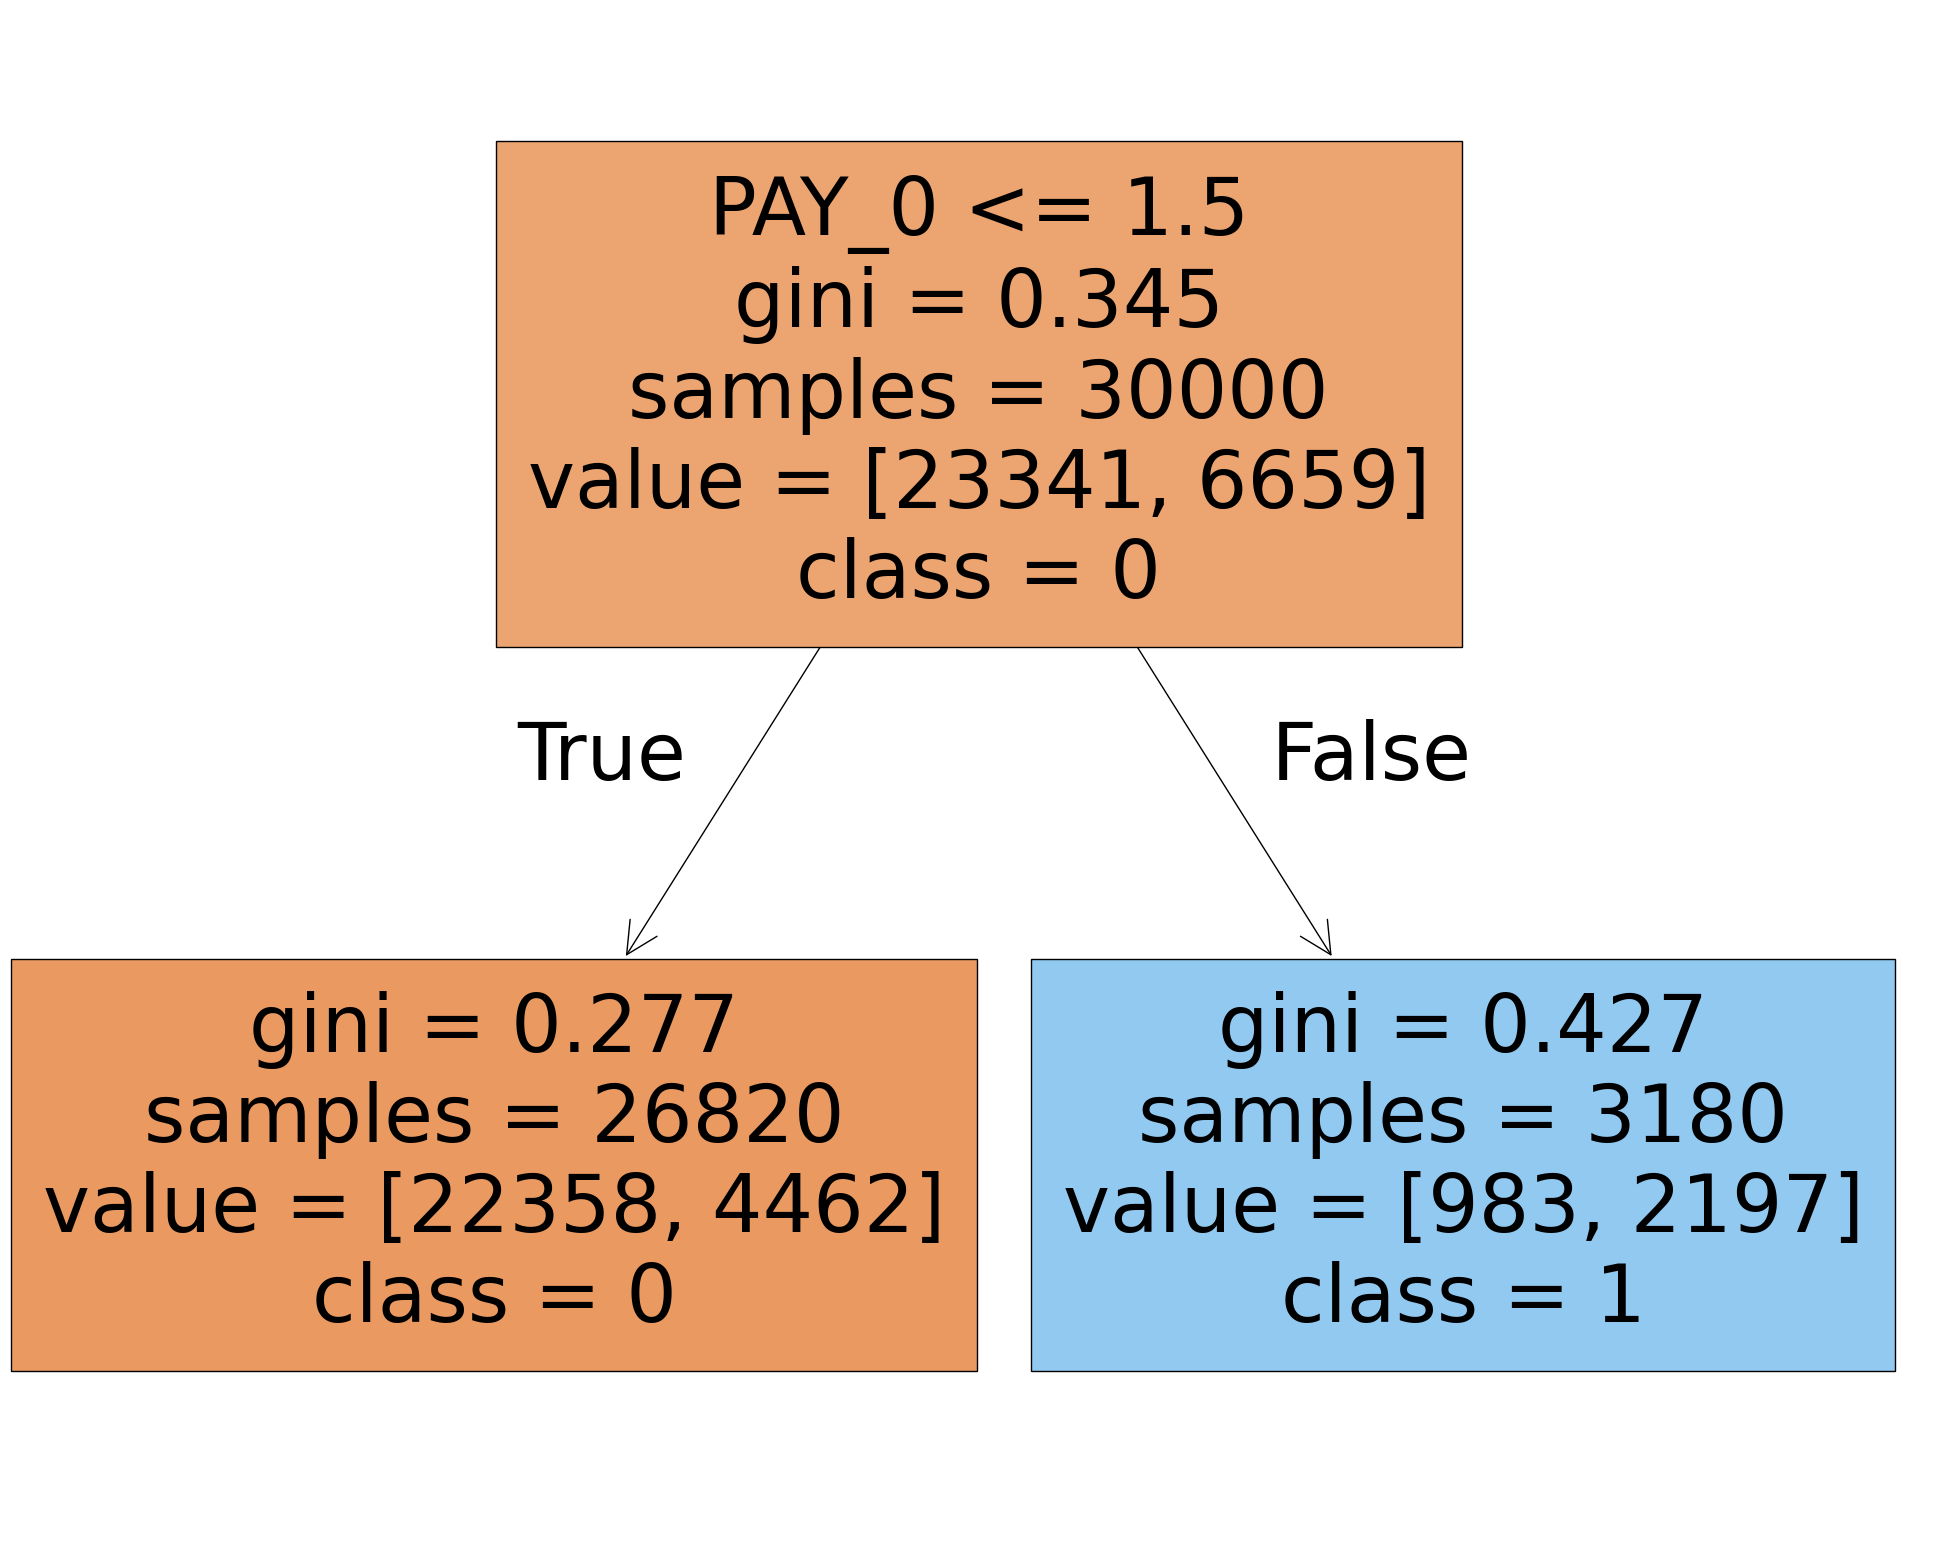

In [11]:
# visualize the stump
# features we used

fn = feats

# labels of the target class

cn = ["0", "1"]


fig = plt.figure(figsize=(25, 20))
_ = tree.plot_tree(weak_l1, feature_names=fn, class_names=cn, filled=True)

# save the figure to file

# fig.savefig('imagename.png')
fig.savefig("decistion_tree.png")

**Hình 1: Gốc cây quyết định của bộ học cơ sở ở vòng lặp đầu tiên**

Lưu ý bộ học cơ sở thấy *Pay_0* là biến dự báo mạnh nhất để chia. Ta so sánh các dự báo với giá trị thực.

In [12]:
data4lesson1["pred1"] = weak_l1.predict(X)

In [13]:
data4lesson1[["Class", "pred1", "probR1"]].head()

,Class,pred1,probR1
ID,,,
6793,0,1,0.000033
1623,0,0,0.000033
24884,0,0,0.000033
19941,0,0,0.000033
16845,1,0,0.000033


### **2.4 Bước 4: Tính hiệu suất**

Ảnh chụp chỉ năm dòng đầu cho thấy một phân loại sai ở ID 16973. Số lần phân loại sai sẽ quyết định *lượng tiếng nói* (amount of say) hay *hiệu suất* của bộ phân loại này.
Công thức của lượng tiếng nói là

$$
\begin{equation}
\text{Lượng tiếng nói} = \frac{1}{2}ln\left( \frac{\text{1 - Tổng sai số}}{\text{Tổng sai số}}\right)
\tag{1.1}
\end{equation}
$$

trong đó **Tổng sai số** đơn giản là tổng trọng số của các quan sát bị phân loại sai. Tổng sai số của bộ phân loại cơ sở ở vòng lặp đầu tiên, tức weak_l1, là

In [14]:
# Total error of weak_l1
E_1 = round(
    np.sum(
        np.where(
            data4lesson1["Class"] != data4lesson1["pred1"], data4lesson1["probR1"], 0
        )
    ),
    5,
)

E_1

np.float64(0.1815)

Lượng tiếng nói trong (1.1) theo tổng sai số nói chung được thể hiện bên dưới.

Text(0.5, 0, 'Total Error')

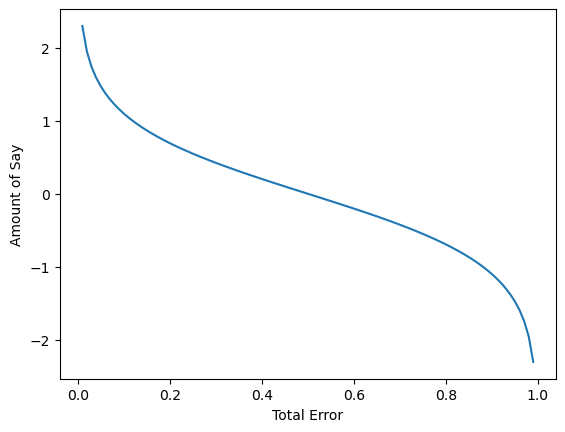

In [15]:
n_pts = 100
TE = 0.01 + np.arange(n_pts) * (1 - 0.01) / n_pts
AoS = 0.5 * np.log((1 - TE) / TE)
plt.plot(TE, AoS)
plt.ylabel("Amount of Say")
plt.xlabel("Total Error")

**Hình 2: Hiệu suất hay lượng tiếng nói theo tổng sai số của một bộ phân loại**

Từ hình 2, ta thấy với phân loại gần như hoàn hảo, bộ phân loại cơ sở sẽ có hiệu suất tiến đến vô cùng. Với phân loại gần như sai hoàn toàn, bộ học sẽ có hiệu suất tiến đến âm vô cùng. Với tổng sai số bằng 0,5, hiệu suất bằng không. Nếu mọi mẫu có trọng số bằng nhau, điều này tương đương một bộ phân loại không có kỹ năng. Trong thực tế, người ta cộng một số hạng sai số nhỏ vào tổng sai số để tránh trường hợp tổng sai số bằng không. Bộ học cơ sở đầu tiên của ta có tổng sai số là 0,1796, cho hiệu suất 0,7596. Hãy nhớ AdaBoost tập trung vào các quan sát phân loại sai bằng cách điều chỉnh trọng số theo từng vòng lặp. Bây giờ ta xem quá trình điều chỉnh trọng số.


Với các quan sát bị phân loại sai, công thức điều chỉnh trọng số là,

$$
\begin{equation}
\text{Trọng số điều chỉnh} = \text{Trọng số hiện tại} \times e^{\text{hiệu suất}}
\tag{1.2}
\end{equation}
$$

tương tự, công thức điều chỉnh trọng số của các quan sát phân loại đúng là,

$$
\begin{equation}
\text{Trọng số điều chỉnh} = \text{Trọng số hiện tại} \times e^{\text{-hiệu suất}}
\tag{1.3}
\end{equation}
$$

Lưu ý khác biệt giữa (1.2) và (1.3) là dấu của số mũ. Điều này có nghĩa các quan sát phân loại đúng bị giảm trọng số, còn các quan sát phân loại sai được điều chỉnh lên trọng số lớn hơn. Áp dụng (1.2) và (1.3) cho các trọng số tạo ra các trọng số mới như bên dưới.

In [16]:
# performance of weak_l1
p1 = 0.5 * np.log((1 - E_1) / E_1)
# Call the new weights `probR2` since it is the second iteration
data4lesson1["probR2"] = np.where(
    data4lesson1["Class"] != data4lesson1["pred1"],
    data4lesson1["probR1"] * np.exp(p1),  # misclassifications (1.2)
    data4lesson1["probR1"] * np.exp(-p1),
)

In [17]:
data4lesson1[["Class", "pred1", "probR1", "probR2"]].head()

,Class,pred1,probR1,probR2
ID,,,,
6793,0,1,0.000033,0.000071
1623,0,0,0.000033,0.000016
24884,0,0,0.000033,0.000016
19941,0,0,0.000033,0.000016
16845,1,0,0.000033,0.000071


Ta thấy các quan sát phân loại đúng có trọng số mới thấp hơn trọng số ban đầu là $3{,}3\times 10^{-5}$, còn các quan sát phân loại sai có trọng số tăng lên. Hãy nhớ trọng số tăng sẽ làm tăng khả năng quan sát đó được chọn khi lấy mẫu có hoàn lại. Một điều cần lưu ý là các trọng số mới được chuẩn hóa để có tổng bằng 1, như các trọng số ban đầu trong cột `probR1`.

In [18]:
# normalize the weights
data4lesson1["probR2"] = data4lesson1["probR2"] / data4lesson1["probR2"].sum()

Điều này đưa ta về Bước 1 với một bộ trọng số mới để lặp lại các bước 2 đến 4. Số lần lặp các chu kỳ này phụ thuộc vào số bộ phân loại yếu mà ta chỉ định. Đây là quá trình lặp mà AdaBoost thực hiện để xây dựng mô hình cuối cùng. Lý tưởng thì ta muốn tiếp tục quá trình này đến khi mọi quan sát được phân loại đúng, nhưng như vậy có thể gây quá khớp. Cần cân nhắc tinh chỉnh siêu tham số. Để minh họa dự báo cuối cùng của mô hình, giả sử ta đã chọn 5 bộ học cơ sở và mỗi bộ có hiệu suất hay lượng tiếng nói và dự báo như sau.

In [19]:
dat = [[0.7596, 1], [0.7821, 1], [0.79019, 1], [0.8241, 0], [0.8410, 0]]
model_summary = pd.DataFrame(data=dat, columns=["performance", "prediction"])
model_summary.index.name = "iteration"
model_summary

,performance,prediction
iteration,,
0,0.75960,1
1,0.78210,1
2,0.79019,1
3,0.82410,0
4,0.84100,0


Kết quả giả định ở trên qua 5 vòng lặp cho thấy 3 bộ học cơ sở dự báo nhóm 1 và 2 bộ học cơ sở dự báo nhóm 0. Phiếu cuối cùng dựa trên tổng hiệu suất của mỗi nhóm được bầu, tức là thay vì dùng số đếm, ta dùng tổng hiệu suất. Phép tính bên dưới cho thấy nhóm 1 được ưu tiên vì tổng hiệu suất của các bộ học cơ sở ủng hộ nhóm đó là 2,332, lớn hơn tổng hiệu suất của các bộ học cơ sở ủng hộ nhóm 0.

In [20]:
class_0 = np.sum(
    np.where(model_summary["prediction"] == 0, model_summary["performance"], 0)
)
class_1 = np.sum(
    np.where(model_summary["prediction"] == 1, model_summary["performance"], 0)
)

print("Weight of Votes ")
print("Class 0: {} Class 1: {}".format(class_0, class_1))

Weight of Votes 
Class 0: 1.6651 Class 1: 2.33189


Cần lưu ý rằng ví dụ trên minh họa thủ tục cập nhật trên toàn bộ tập dữ liệu, trong khi thực tế ta dùng tập huấn luyện để cập nhật và xây dựng AdaBoost. Ta cũng minh họa quá trình bằng các gốc cây quyết định yếu, nhưng có bằng chứng cho thấy các bộ học nâng cao hơn cũng hiệu quả (Chuan et al. 3).

Boosting đã thành công trong lĩnh vực khoa học dữ liệu, đặc biệt là trong các cuộc thi Kaggle. Còn một kỹ thuật boosting nữa mà ta sẽ nói ở bài tiếp theo, gọi là gradient boosting.

## **3. Kết luận**

Bài này tập trung vào boosting thích nghi và cho thấy thủ tục cập nhật lặp để ra mô hình và dự báo cuối cùng. Thủ tục được trình bày cho bài toán phân loại, cụ thể là dự báo vỡ nợ thanh toán thẻ tín dụng. Ở bài tiếp theo, ta sẽ xem một thuật toán boosting khác là gradient boosting và so sánh mọi phương pháp học tập kết hợp đã nói trong module này trên cùng một bài toán.

**Tài liệu tham khảo**

1. Chuan, Yijian, et al. "The Success of AdaBoost and Its Application in Portfolio Management." *arXiv*, 2021, pp. 1–6.
2. University of California, Irvine Machine Learning Repository. "Default of Credit Card Clients." https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients